# ML-10 — Content Action Playbook

This notebook converts the transparent Week-7 baseline score into a human-reviewed content action playbook. It is decision support for a small review queue, not an automated publishing system. All findings below are descriptive associations in one 30,000-row snapshot.


## 1. Ranked actions + reason codes

The baseline ranks pages for review when they are both stale (`days_since_last_update >= 180`) and visible (`impressions_90d >= 500`). Within that transparent rule, higher observed impressions means a larger audience to review first. The queue is a prioritisation aid: it does not say that a refresh will improve performance.

Reason codes keep the recommendation explainable. `stale_visible` means the page meets the baseline rule; `fresh_or_low_visibility` means it is outside the refresh-review rule and should be monitored rather than automatically changed. The archetype mapping adds a human-checkable next step based on age, visibility, and observed position.


In [4]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

start = Path.cwd().resolve()
root = next(
    (
        p
        for p in [start, *start.parents]
        if (p / "data" / "raw" / "content_refresh_anonymized.csv").exists()
    ),
    None,
)

if root is None:
    raise FileNotFoundError("Repository root with the starter CSV was not found")

data_path = root / "data" / "raw" / "content_refresh_anonymized.csv"
output_dir = root / "work" / "outputs"
figure_dir = root / "work" / "figures"
output_dir.mkdir(parents=True, exist_ok=True)
figure_dir.mkdir(parents=True, exist_ok=True)

df = pd.read_csv(data_path)

required = {
    "content_id",
    "client_id",
    "impressions_90d",
    "days_since_last_update",
    "avg_position",
    "ctr",
    "content_age_days",
}
missing = required - set(df.columns)
if missing:
    raise ValueError(f"Missing required columns: {sorted(missing)}")

stale_visible = (
    (df["days_since_last_update"] >= 180)
    & (df["impressions_90d"] >= 500)
)

df["reason_code"] = np.where(
    stale_visible, "stale_visible", "fresh_or_low_visibility"
)
df["action_label"] = np.where(
    stale_visible, "refresh_review", "monitor"
)
df["score"] = np.where(
    stale_visible, df["impressions_90d"], 0
).astype(float)

df["archetype"] = np.select(
    [
        stale_visible
        & (df["avg_position"] > 0)
        & (df["avg_position"] <= 20),
        stale_visible
        & ((df["avg_position"] > 20) | (df["avg_position"] == 0)),
        ~stale_visible & (df["impressions_90d"] >= 500),
    ],
    [
        "stale_visible_striking",
        "stale_visible_deep_or_unknown",
        "recent_or_lower_priority_visible",
    ],
    default="low_visibility_monitor",
)

df["recommended_action"] = df["archetype"].map(
    {
        "stale_visible_striking": (
            "Review intent, title, outline, and outdated claims "
            "before a targeted refresh"
        ),
        "stale_visible_deep_or_unknown": (
            "Check indexing, intent fit, and content quality "
            "before deciding whether to refresh"
        ),
        "recent_or_lower_priority_visible": (
            "Monitor; do not refresh solely from this score"
        ),
        "low_visibility_monitor": (
            "Monitor measurement and visibility; "
            "no automatic content change"
        ),
    }
)

queue = (
    df.sort_values(
        ["score", "impressions_90d", "content_id"],
        ascending=[False, False, True],
    )
    .reset_index(drop=True)
)

queue.insert(0, "rank", np.arange(1, len(queue) + 1))

queue_columns = [
    "rank",
    "content_id",
    "client_id",
    "score",
    "reason_code",
    "action_label",
    "archetype",
    "recommended_action",
    "impressions_90d",
    "days_since_last_update",
    "avg_position",
    "ctr",
    "content_age_days",
]
queue = queue[queue_columns]

print(
    f"Rows scored: {len(df):,}; "
    f"refresh-review rows: {stale_visible.sum():,}; "
    f"monitor rows: {(~stale_visible).sum():,}"
)

print(
    f"Top review score: {queue.iloc[0]['score']:,.0f}; "
    "clients represented in review queue: "
    f"{queue.loc[queue['action_label'].eq('refresh_review'), 'client_id'].nunique():,}"
)

display(queue.head(10))
display(
    queue.groupby(
        ["reason_code", "action_label"], as_index=False
    ).agg(
        rows=("content_id", "size"),
        median_impressions=("impressions_90d", "median"),
        median_days_stale=("days_since_last_update", "median"),
    )
)

assert len(queue) == len(df)
assert queue["rank"].is_unique
assert queue["content_id"].is_unique
assert (
    set(
        queue.loc[
            queue["action_label"].eq("refresh_review"),
            "reason_code",
        ]
    )
    == {"stale_visible"}
)


Rows scored: 30,000; refresh-review rows: 17; monitor rows: 29,983
Top review score: 61,678; clients represented in review queue: 4


,rank,content_id,client_id,score,reason_code,action_label,archetype,recommended_action,impressions_90d,days_since_last_update,avg_position,ctr,content_age_days
0,1,content_cf56e2e2e282,client_7f2253d7e2,61678.0,stale_visible,refresh_review,stale_visible_striking,"Review intent, title, outline, and outdated cl...",61678,194,19.7,0.15,231
1,2,content_7368877ea310,client_7f2253d7e2,59472.0,stale_visible,refresh_review,stale_visible_deep_or_unknown,"Check indexing, intent fit, and content qualit...",59472,194,24.8,0.13,231
2,3,content_1bfaa38ff26c,client_7f2253d7e2,25715.0,stale_visible,refresh_review,stale_visible_deep_or_unknown,"Check indexing, intent fit, and content qualit...",25715,194,22.2,0.23,231
3,4,content_0a91db491d14,client_7f2253d7e2,13299.0,stale_visible,refresh_review,stale_visible_striking,"Review intent, title, outline, and outdated cl...",13299,193,10.5,0.49,231
4,5,content_5feee3994adb,client_7f2253d7e2,7812.0,stale_visible,refresh_review,stale_visible_deep_or_unknown,"Check indexing, intent fit, and content qualit...",7812,194,39.0,0.01,231
5,6,content_c2d929d83eaa,client_7f2253d7e2,7558.0,stale_visible,refresh_review,stale_visible_striking,"Review intent, title, outline, and outdated cl...",7558,193,17.9,0.20,231
6,7,content_b16bd7307b39,client_7f2253d7e2,4590.0,stale_visible,refresh_review,stale_visible_deep_or_unknown,"Check indexing, intent fit, and content qualit...",4590,194,31.0,0.00,231
7,8,content_fe16a55cd13d,client_7f2253d7e2,4556.0,stale_visible,refresh_review,stale_visible_striking,"Review intent, title, outline, and outdated cl...",4556,194,16.4,0.33,231
8,9,content_ecb6215e79fd,client_7f2253d7e2,4429.0,stale_visible,refresh_review,stale_visible_deep_or_unknown,"Check indexing, intent fit, and content qualit...",4429,194,25.3,0.38,231
9,10,content_928af3e22c80,client_7f2253d7e2,1697.0,stale_visible,refresh_review,stale_visible_striking,"Review intent, title, outline, and outdated cl...",1697,193,15.8,0.12,231


,reason_code,action_label,rows,median_impressions,median_days_stale
0,fresh_or_low_visibility,monitor,29983,731.0,20.0
1,stale_visible,refresh_review,17,4429.0,194.0


## 2. Intended use and limits

**Intended use.** A content strategist can use the ranked queue as a weekly triage list: open the highest-ranked pages, inspect the page and search intent, then decide whether a refresh brief is worthwhile. The score is deliberately transparent and uses only snapshot fields available before any proposed action.

**Limits.** This is one pseudonymised, trailing-90-day snapshot across 32 clients. It ranks observed audience and staleness; it does not estimate incremental traffic, causal lift, revenue, or search-engine behaviour. The queue is not calibrated for equal client effort, does not replace editorial or legal review, and should not be treated as a production SLA. A zero position is treated as unknown, not as a best rank, and small-volume rates should be read cautiously.

**Cost/value lens.** Start with the small 17-item refresh-review queue because review time is the immediate cost. Prioritise high-impression items only after a human confirms that the likely editorial effort is proportionate to the visible audience and that the page has a clear, safe improvement path. Treat expected value as a hypothesis to measure later—not as revenue or lift implied by the score—and stop when review effort, risk, or weak evidence outweighs the observed opportunity.

**Archetype → action mapping.** `stale_visible_striking` is a high-visibility page with an observed average position at or above the top-20 boundary: inspect intent, title, outline, freshness, and factual accuracy for a targeted refresh. `stale_visible_deep_or_unknown` is stale and visible but deep or missing position data: first check indexing, intent fit, and measurement. The two monitor archetypes are deliberately non-intervention recommendations; they need observation rather than an automatic rewrite.


In [5]:
archetype_summary = (queue.groupby('archetype', as_index=False)
    .agg(rows=('content_id', 'size'), median_score=('score', 'median'), median_ctr=('ctr', 'median'), median_position=('avg_position', 'median'))
    .sort_values('rows', ascending=False))
display(archetype_summary)
assert set(queue['archetype']) <= {'stale_visible_striking', 'stale_visible_deep_or_unknown', 'recent_or_lower_priority_visible', 'low_visibility_monitor'}


,archetype,rows,median_score,median_ctr,median_position
1,recent_or_lower_priority_visible,16709,0.0,0.17,11.2
0,low_visibility_monitor,13274,0.0,0.00,10.1
3,stale_visible_striking,10,1552.5,0.24,16.1
2,stale_visible_deep_or_unknown,7,4590.0,0.13,25.3


## 3. Human review + the no-go list

A person must review every proposed refresh before work begins. They should confirm the page still matches the intended audience and query, check current facts and citations, look for cannibalisation or duplicate intent, inspect technical/indexing status, and record the decision plus rationale. A reviewer can reject, defer, or re-rank any item; the queue is not an approval.

**Never automate:** publishing or overwriting content; changing medical, financial, legal, safety, or regulated advice; making claims about competitors or people; deleting pages or redirecting URLs; selecting facts or sources without verification; changing canonical/indexing settings; or inferring business value, causality, or guaranteed ranking gains from this score. The notebook intentionally exports pseudonymous IDs and aggregate fields only—no client names, URLs, or private queries.


In [6]:
review_checklist = pd.DataFrame([
    ['Intent and audience', 'Confirm the page serves the intended query and audience today.'],
    ['Evidence and safety', 'Verify facts, citations, claims, and regulated-topic requirements.'],
    ['Technical context', 'Check indexing, canonical, duplicate intent, and measurement quality.'],
    ['Decision record', 'Record approve, defer, reject, or re-rank with a reason before any brief is created.'],
], columns=['review_gate', 'human_check'])
display(review_checklist)
print(f'Every refresh_review row requires human review: {queue["action_label"].eq("refresh_review").sum():,} rows.')


,review_gate,human_check
0,Intent and audience,Confirm the page serves the intended query and...
1,Evidence and safety,"Verify facts, citations, claims, and regulated..."
2,Technical context,"Check indexing, canonical, duplicate intent, a..."
3,Decision record,"Record approve, defer, reject, or re-rank with..."


Every refresh_review row requires human review: 17 rows.


## 4. Monitoring / retrain triggers

The playbook should be rechecked at each new snapshot. Monitor queue size and score distribution, missingness, client representation, the stale/visible rates, and reviewer outcomes. A refresh is not counted as successful unless a later, comparable measurement window is available; before/after changes are descriptive and may reflect seasonality or selection.

**Retrain or re-validate when:** the data contract or metric definitions change; the snapshot window or population changes; more than 10% of rows have unexpected missingness or schema drift; the refresh-review share moves by more than 10 percentage points from this baseline; reviewer override/rejection exceeds 30% for two consecutive reviews; or the queue becomes concentrated in one client or archetype without a documented business reason. Do not silently tune thresholds to chase an outcome—re-run the validation and document the new rule.


In [7]:
monitoring_baseline = {
    'rows': int(len(df)),
    'clients': int(df['client_id'].nunique()),
    'refresh_review_share': float(stale_visible.mean()),
    'top_score': float(queue.iloc[0]['score']),
    'median_score_among_reviews': float(queue.loc[queue['action_label'].eq('refresh_review'), 'score'].median()),
    'missingness_alert_threshold': 0.10,
    'review_share_drift_alert_pp': 10.0,
    'override_rate_alert': 0.30,
}
display(pd.DataFrame([monitoring_baseline]))
assert 0 <= monitoring_baseline['refresh_review_share'] <= 1


,rows,clients,refresh_review_share,top_score,median_score_among_reviews,missingness_alert_threshold,review_share_drift_alert_pp,override_rate_alert
0,30000,32,0.000567,61678.0,4429.0,0.1,10.0,0.3


## 5. Exports for the paper

The queue is regenerated from the starter data and saved to `work/outputs/action_playbook_queue.csv`. It is a derived data file and should remain out of git under the repository leak-guard. The compact JSON and figure are paper receipts that document the rule and the queue composition; the notebook remains the source of truth.


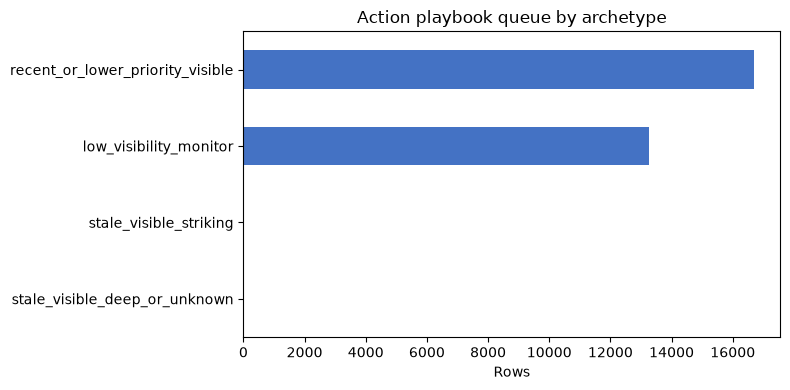

Wrote D:\FlyRank-ML-Internship-Starter\work\outputs\action_playbook_queue.csv
Wrote D:\FlyRank-ML-Internship-Starter\work\figures\action_playbook_archetypes.png


In [8]:
queue_path = output_dir / 'action_playbook_queue.csv'
figure_path = figure_dir / 'action_playbook_archetypes.png'

queue.to_csv(queue_path, index=False)
counts = queue['archetype'].value_counts().sort_values()
ax = counts.plot(
    kind='barh',
    figsize=(8, 4),
    color='#4472C4',
    title='Action playbook queue by archetype',
)
ax.set_xlabel('Rows')
ax.set_ylabel('')
plt.tight_layout()
plt.savefig(figure_path, dpi=160)
plt.show()
print(f'Wrote {queue_path}')
print(f'Wrote {figure_path}')
assert queue_path.exists() and figure_path.exists()


## Self-check

- [x] Ranked actions, reason codes, and archetype-to-action mapping are explicit.
- [x] Intended use, limits, human review rules, no-go cases, cost/value framing, and monitoring triggers are stated.
- [x] The queue and paper summary are regenerated under `work/outputs/`; the reusable figure is under `work/figures/`.
- [x] Claims use observed, descriptive, and decision-support language; no causal lift is claimed.
- [x] IDs remain pseudonymous and no client names, URLs, or private queries are exported.

Run the notebook top to bottom before committing. The queue CSV is intentionally a local generated export; commit this notebook, the JSON receipt, and the figure if your repository's leak-guard permits them.
